# Analysis of frequency change fits

In [1]:
import arviz as az
import bambi as bmb
import polars as  pl
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

from kidney.contrasts import get_t_groups, get_overall_effects, get_gtyp_given_sex_age, get_sex_given_gtyp_age
from kidney.paths import RESULTS_DIR_NEW, PREPARED_FILES_NEW, PLOT_DIR_NEW
from kidney.plotting import forestplot_oz, plot_ppc, set_symmetric_xlim
from kidney.sign_probs import get_sign_probs, get_signif

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
az.rcParams["data.load"] = "eager"
PLOT_DIR_NEW.mkdir(exist_ok=True)

In [3]:
idata_vehicle = az.from_netcdf(RESULTS_DIR_NEW / "idata_frequency_vehicle_change.nc")
idata_empa = az.from_netcdf(RESULTS_DIR_NEW / "idata_frequency_empa_change.nc")
msts_vehicle = pl.read_csv(PREPARED_FILES_NEW["frequency_vehicle"])
msts_empa = pl.read_csv(PREPARED_FILES_NEW["frequency_empa"])

In [4]:
print("Vehicle:")
display(az.summary(idata_vehicle, var_names=["~mu", "~1|rat", "~sigma"]))
print("Empa:")
display(az.summary(idata_empa, var_names=["~mu", "~1|rat", "~sigma"]))

Vehicle:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.062,0.018,0.029,0.096,0.000,0.000,1374.0,1845.0,1.00
activity_type[single],0.012,0.007,-0.003,0.025,0.000,0.000,3560.0,3213.0,1.00
gtyp[fa/fa],-0.031,0.026,-0.082,0.018,0.001,0.001,1314.0,1721.0,1.00
age[Young],-0.028,0.024,-0.078,0.014,0.001,0.000,1448.0,2194.0,1.00
sex[M],0.012,0.024,-0.031,0.061,0.001,0.001,1442.0,1903.0,1.00
"gtyp:age[fa/fa, Young]",0.050,0.035,-0.014,0.116,0.001,0.001,1401.0,1932.0,1.01
"gtyp:sex[fa/fa, M]",-0.042,0.036,-0.111,0.022,0.001,0.001,1458.0,1953.0,1.00
1|rat_sigma,0.043,0.007,0.031,0.056,0.000,0.000,1219.0,2248.0,1.00


Empa:


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Intercept,0.065,0.036,0.002,0.133,0.001,0.001,1407.0,1992.0,1.0
activity_type[single],0.003,0.010,-0.017,0.022,0.000,0.000,4176.0,2785.0,1.0
gtyp[fa/fa],-0.028,0.052,-0.134,0.066,0.001,0.001,1659.0,1853.0,1.0
age[Young],-0.007,0.055,-0.111,0.096,0.001,0.001,1982.0,2234.0,1.0
sex[M],0.032,0.052,-0.063,0.131,0.001,0.001,1846.0,2165.0,1.0
"gtyp:age[fa/fa, Young]",0.080,0.074,-0.069,0.213,0.002,0.002,1771.0,2122.0,1.0
"gtyp:sex[fa/fa, M]",-0.093,0.072,-0.234,0.036,0.002,0.001,1854.0,2058.0,1.0
1|rat_sigma,0.087,0.016,0.059,0.115,0.000,0.000,1223.0,2068.0,1.0


## Posterior predictive checks

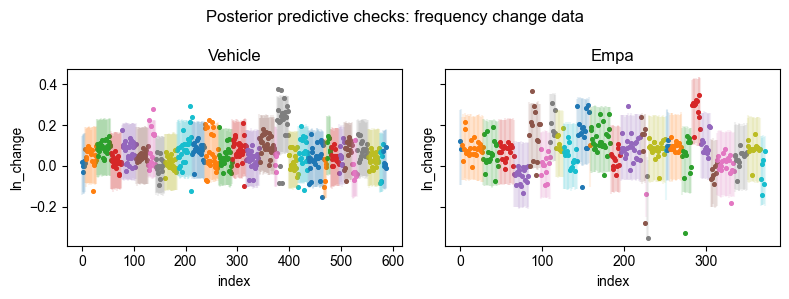

In [6]:
f, axes = plt.subplots(1, 2, figsize=[8, 3], sharey=True)
for ax, idata, name, msts in zip(
    axes,
    (idata_vehicle, idata_empa),
    ("vehicle", "empa"),
    (msts_vehicle, msts_empa),
):
    ax = plot_ppc(ax, idata, msts, ycol="ln_change", groupcol="rat")
    ax.set_title(name.capitalize());
    ax.get_legend().remove()

f.suptitle("Posterior predictive checks: frequency change data");
f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ppc_frequency_change.png", bbox_inches="tight", dpi=200)

Each dot is a vessel, sorted by rat; lines are 1%-99% posterior predictive intervals.

## Effects

Contrasts follow the brief. The overall effect of a factor is averaged with equal weights over the levels of the other factors, e.g. the overall gtyp effect is the mean of fa/fa - fa/+ over the four age/sex groups. The gtyp effect given sex is averaged over age, and vice versa. SP is the posterior probability that the contrast is positive; lines are 95% intervals.

In [7]:
def plot_effects(ts_vehicle, ts_empa, figsize):
    f, axes = plt.subplots(1, 2, figsize=figsize)
    for ax, ts, tle in zip(axes, (ts_vehicle, ts_empa), ("Vehicle", "Empa")):
        ax = forestplot_oz(ax, ts, xlabel="TS (ln injected/baseline)", sign_probs=True)
        set_symmetric_xlim(ax, ts, pad=1.8)
        ax.set_title(tle)
        ax.spines[['top', 'right', 'left']].set_visible(False)
    axes[1].set_yticks([], [])
    return f, axes


t_groups_vehicle, t_groups_empa = (get_t_groups(idata) for idata in (idata_vehicle, idata_empa))
overall_ts_vehicle, overall_ts_empa = (
    get_overall_effects(t_groups) | {
        # activity_type's reference level is double, so negate to get double - single
        "double - single": -idata.posterior["activity_type"].sel(activity_type_dim="single", drop=True),
    }
    for idata, t_groups in ((idata_vehicle, t_groups_vehicle), (idata_empa, t_groups_empa))
)
gtyp_ts_vehicle, gtyp_ts_empa = (get_gtyp_given_sex_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))

### Overall effects

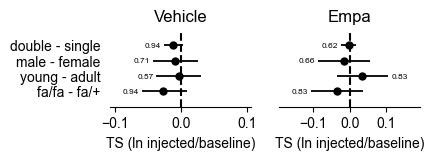

In [13]:
f, axes = plot_effects(overall_ts_vehicle, overall_ts_empa, figsize=(4, 1))
# f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_frequency_change_overall.pdf", bbox_inches="tight", dpi=200)

### Effect of gtyp given sex and given age

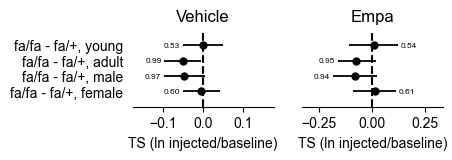

In [18]:
f, axes = plot_effects(gtyp_ts_vehicle, gtyp_ts_empa, figsize=(4, 1))
# f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_frequency_change_gtyp_given_sex_age.pdf", bbox_inches="tight", dpi=200)

### Effect of sex given gtyp and given age

In [15]:
sex_ts_vehicle, sex_ts_empa = (get_sex_given_gtyp_age(t_groups) for t_groups in (t_groups_vehicle, t_groups_empa))

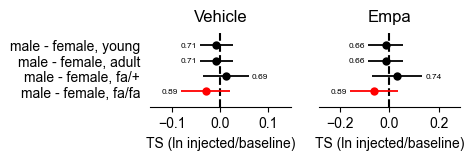

In [17]:
f, axes = plot_effects(sex_ts_vehicle, sex_ts_empa, figsize=(4, 1))
# f.tight_layout()
f.savefig(PLOT_DIR_NEW / "ts_frequency_change_sex_given_gtyp_age.pdf", bbox_inches="tight", dpi=200)

## Show sign probabilities in tables

In [22]:
sp_all = pd.concat(
    objs=[
        pd.DataFrame({
            "vehicle": get_sign_probs(ts_vehicle),
            "vehicle_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_vehicle).items()},
            "empa": get_sign_probs(ts_empa),
            "empa_signif": {k: get_signif(v) for k, v in get_sign_probs(ts_empa).items()},
        })
        for ts_vehicle, ts_empa in (
            (overall_ts_vehicle, overall_ts_empa),
            (gtyp_ts_vehicle, gtyp_ts_empa),
            (sex_ts_vehicle, sex_ts_empa),
        )
    ],
    keys=("overall", "gtyp given sex/age", "sex given age/gtyp"),
    names=("contrast", "group"),
)
sp_all

vehicle vehicle_signif     empa  \
contrast           group                                                   
overall            fa/fa - fa/+          0.06025                 0.16875   
                   young - adult         0.43100                 0.83475   
                   male - female         0.29350                 0.34000   
                   double - single       0.05825                 0.38275   
gtyp given sex/age fa/fa - fa/+, female  0.40050                 0.60750   
                   fa/fa - fa/+, male    0.03375                 0.05900   
                   fa/fa - fa/+, adult   0.01375              *  0.05225   
                   fa/fa - fa/+, young   0.47300                 0.53925   
sex given age/gtyp male - female, fa/fa  0.11325                 0.10525   
                   male - female, fa/+   0.68650                 0.73850   
                   male - female, adult  0.29350                 0.34000   
                   male - female, young  0.29350                 0.34000   

                                        empa_signif  
contrast           group                             
overall            fa/fa - fa/+                      
                   young - adult                     
                   male - female                     
                   double - single                   
gtyp given sex/age fa/fa - fa/+, female              
                   fa/fa - fa/+, male                
                   fa/fa - fa/+, adult               
                   fa/fa - fa/+, young               
sex given age/gtyp male - female, fa/fa              
                   male - female, fa/+               
                   male - female, adult              
                   male - female, young